In [2]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


Mean target_aver_OneDnSE:
IVF-Zygote 0.4245
IVF-2C 0.3082
IVF-4C 0.2727


/home/lihaoxing/tmp/ipykernel_21189/866798659.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_21189/866798659.py:49: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IVF-Zygote vs. IVF-2C: Mann-Whitney-Wilcoxon test two-sided, P_val:1.206e-05 U_stat=1.968e+03
IVF-2C vs. IVF-4C: Mann-Whitney-Wilcoxon test two-sided, P_val:8.536e-04 U_stat=1.231e+04


/home/lihaoxing/tmp/ipykernel_21189/866798659.py:133: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ordered_phenotypes, fontsize=16)


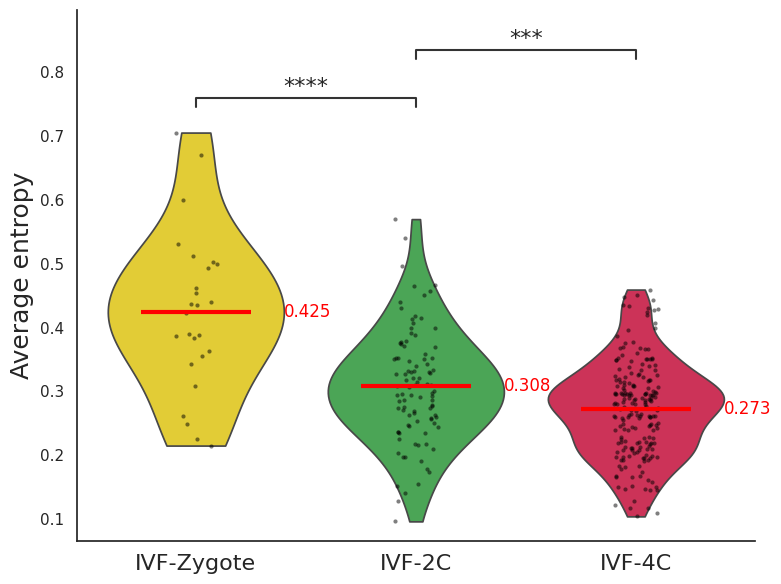

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")  # ⭐统一论文风格（无grid）

# =========================
# 读取数据
# =========================
data = pd.read_csv('532_500k_w10_OneDnSE_CytoTRACE_subTAD.txt', sep='\t')

# =========================
# group & order
# =========================
ordered_phenotypes = ["IVF-Zygote", "IVF-2C", "IVF-4C"]

color_mapping = {
    "PA-MII": "#ffe119",
    "PA-2C": "#3cb44b",
    "PA-4C": "#e6194b",
    "IVF-Zygote": "#ffe119",
    "IVF-2C": "#3cb44b",
    "IVF-4C": "#e6194b"
}

# =========================
# mean value
# =========================
means = data.groupby("Phenotype")["target_aver_OneDnSE"].mean().reindex(ordered_phenotypes)

print("Mean target_aver_OneDnSE:")
for k, v in means.items():
    print(k, f"{v:.4f}")

# =========================
# figure
# =========================
fig, ax = plt.subplots(figsize=(8, 6))

# =========================
# violin
# =========================
sns.violinplot(
    x="Phenotype",
    y="target_aver_OneDnSE",
    data=data,
    order=ordered_phenotypes,
    palette=color_mapping,
    inner=None,
    cut=0,
    scale="width",
    ax=ax
)

# =========================
# strip (black points)
# =========================
sns.stripplot(
    x="Phenotype",
    y="target_aver_OneDnSE",
    data=data,
    order=ordered_phenotypes,
    color="black",
    size=3,
    alpha=0.5,
    jitter=True,
    ax=ax
)

# =========================
# mean line + value (red)
# =========================
for i, g in enumerate(ordered_phenotypes):
    m = means[g]

    ax.hlines(
        y=m,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color="red",
        linewidth=3,
        zorder=5
    )

    ax.text(
        i + 0.4,
        m,
        f"{m:.3f}",
        color="red",
        fontsize=12,
        va="center"
    )

# =========================
# statistics
# =========================
pairs = [
    ("IVF-Zygote", "IVF-2C"),
    ("IVF-2C", "IVF-4C")
]

annotator = Annotator(
    ax,
    pairs,
    data=data,
    x="Phenotype",
    y="target_aver_OneDnSE",
    order=ordered_phenotypes
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    fontsize=16
)

annotator.apply_and_annotate()

# =========================
# labels & style
# =========================
ax.set_ylabel("Average entropy", fontsize=18)
ax.set_xlabel("")
#ax.set_title("IVF entropy trajectory", fontsize=20)

ax.set_xticklabels(ordered_phenotypes, fontsize=16)

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("IVF_entropy_styled.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_1858433/3561852206.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_1858433/3561852206.py:59: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IVF-TLD-2α vs. IVF-TLD-2β: Mann-Whitney-Wilcoxon test two-sided, P_val:3.383e-01 U_stat=1.079e+03
IVF-TLD-4α vs. IVF-TLD-4β: Mann-Whitney-Wilcoxon test two-sided, P_val:4.977e-01 U_stat=3.689e+03


/home/lihaoxing/tmp/ipykernel_1858433/3561852206.py:139: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(


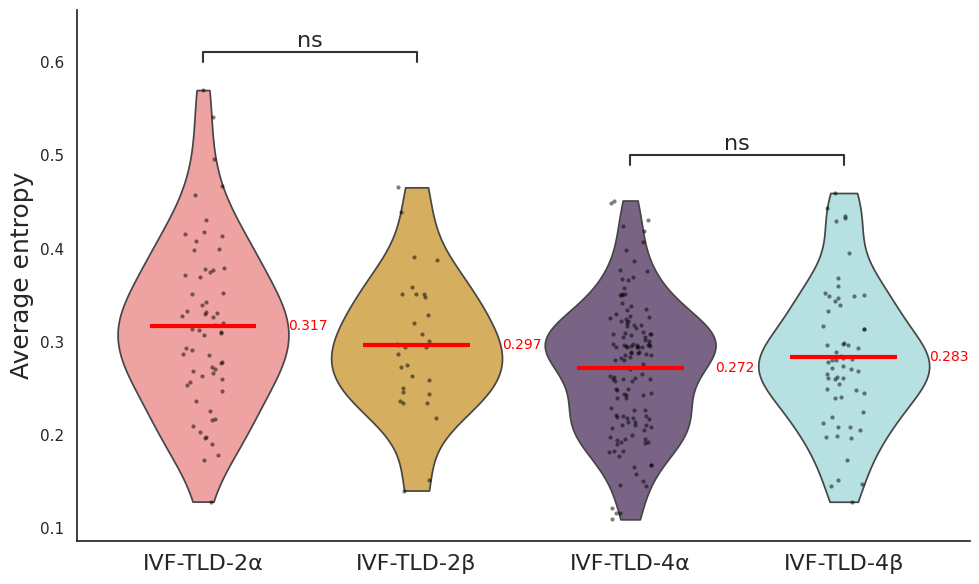

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

# =========================
# data
# =========================
data = pd.read_csv('532_500k_w10_OneDnSE_CytoTRACE_TAD.txt', sep='\t')

# =========================
# ID 替换：旧标签 -> 新标签（iDET -> TLD）
# =========================
id_mapping = {
    "IVF-2C-C1": "IVF-TLD-2α",
    "IVF-2C-C2": "IVF-TLD-2β",
    "IVF-4C-D1": "IVF-TLD-4α",
    "IVF-4C-D2": "IVF-TLD-4β",
}

data['Phenotype2'] = data['Phenotype2'].replace(id_mapping)

sns.set(style="white")

# =========================
# color
# =========================
color_mapping = {
    "IVF-TLD-2α": "#fb9795",
    "IVF-TLD-2β": "#E9B44C",
    "IVF-TLD-4α": "#7c5e8c",
    "IVF-TLD-4β": "#b0e7ea",
}

trajectory_2 = [
    "IVF-TLD-2α",
    "IVF-TLD-2β",
    "IVF-TLD-4α",
    "IVF-TLD-4β",
]

# =========================
# mean
# =========================
means = data.groupby("Phenotype2")["target_aver_OneDnSE"].mean().reindex(trajectory_2)

# =========================
# figure
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

# =========================
# violin
# =========================
sns.violinplot(
    x="Phenotype2",
    y="target_aver_OneDnSE",
    data=data,
    order=trajectory_2,
    palette=color_mapping,
    inner=None,
    cut=0,
    scale="width",
    ax=ax
)

# =========================
# strip
# =========================
sns.stripplot(
    x="Phenotype2",
    y="target_aver_OneDnSE",
    data=data,
    order=trajectory_2,
    color="black",
    size=3,
    alpha=0.5,
    jitter=True,
    ax=ax
)

# =========================
# mean line + value
# =========================
for i, g in enumerate(trajectory_2):
    m = means[g]

    ax.hlines(
        y=m,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color="red",
        linewidth=3,
        zorder=5
    )

    ax.text(
        i + 0.4,
        m,
        f"{m:.3f}",
        color="red",
        fontsize=10,
        va="center"
    )

# =========================
# significance：使用新标签
# =========================
pairs = [
    ("IVF-TLD-2α", "IVF-TLD-2β"),
    ("IVF-TLD-4α", "IVF-TLD-4β")
]

annotator = Annotator(
    ax,
    pairs,
    data=data,
    x="Phenotype2",
    y="target_aver_OneDnSE",
    order=trajectory_2
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    fontsize=16
)

annotator.apply_and_annotate()

# =========================
# x labels：直接使用新标签
# =========================
ax.set_xticklabels(
    ["IVF-TLD-2α", "IVF-TLD-2β", "IVF-TLD-4α", "IVF-TLD-4β"],
    fontsize=16
)

# =========================
# style
# =========================
ax.set_ylabel("Average entropy", fontsize=18)
ax.set_xlabel("")

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("IVF_entropy_clusters_styled.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_21189/3859431405.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_21189/3859431405.py:42: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

PA-MII vs. PA-2C: Mann-Whitney-Wilcoxon test two-sided, P_val:7.715e-10 U_stat=2.011e+03
PA-2C vs. PA-4C: Mann-Whitney-Wilcoxon test two-sided, P_val:1.888e-03 U_stat=5.024e+03


/home/lihaoxing/tmp/ipykernel_21189/3859431405.py:122: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ordered_phenotypes, fontsize=16)


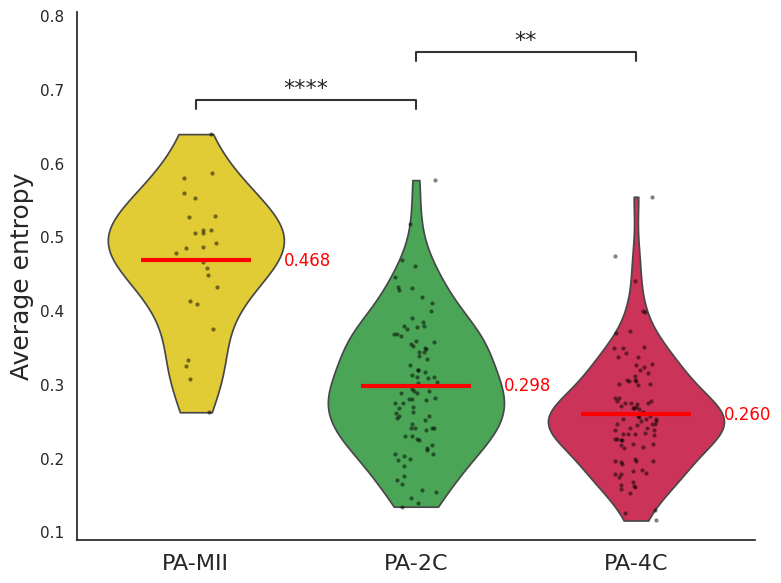

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# =========================
# data
# =========================
data = pd.read_csv('532_500k_w10_OneDnSE_CytoTRACE_subTAD.txt', sep='\t')

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")

# =========================
# color
# =========================
color_mapping = {
    "PA-MII": "#ffe119",
    "PA-2C": "#3cb44b",
    "PA-4C": "#e6194b",
}

trajectory_1 = ["PA-MII", "PA-2C", "PA-4C"]
ordered_phenotypes = trajectory_1

# =========================
# mean
# =========================
means = data.groupby("Phenotype")["target_aver_OneDnSE"].mean().reindex(ordered_phenotypes)

# =========================
# figure
# =========================
fig, ax = plt.subplots(figsize=(8, 6))

# =========================
# violin (clean)
# =========================
sns.violinplot(
    x="Phenotype",
    y="target_aver_OneDnSE",
    data=data,
    order=ordered_phenotypes,
    palette=color_mapping,
    inner=None,
    cut=0,
    scale="width",
    ax=ax
)

# =========================
# strip (black)
# =========================
sns.stripplot(
    x="Phenotype",
    y="target_aver_OneDnSE",
    data=data,
    order=ordered_phenotypes,
    color="black",
    size=3,
    alpha=0.5,
    jitter=True,
    ax=ax
)

# =========================
# mean line + value
# =========================
for i, g in enumerate(ordered_phenotypes):
    m = means[g]

    ax.hlines(
        y=m,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color="red",
        linewidth=3,
        zorder=5
    )

    ax.text(
        i + 0.4,
        m,
        f"{m:.3f}",
        color="red",
        fontsize=12,
        va="center"
    )

# =========================
# statistics
# =========================
pairs = [
    ("PA-MII", "PA-2C"),
    ("PA-2C", "PA-4C")
]

annotator = Annotator(
    ax,
    pairs,
    data=data,
    x="Phenotype",
    y="target_aver_OneDnSE",
    order=ordered_phenotypes
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    fontsize=16
)

annotator.apply_and_annotate()

# =========================
# labels
# =========================
ax.set_xticklabels(ordered_phenotypes, fontsize=16)

ax.set_ylabel("Average entropy", fontsize=18)
ax.set_xlabel("")
#ax.set_title("PA entropy trajectory", fontsize=20)

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("PA_entropy_styled.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_21189/3447031972.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/lihaoxing/tmp/ipykernel_21189/3447031972.py:50: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

PA-2C-A1 vs. PA-2C-A2: Mann-Whitney-Wilcoxon test two-sided, P_val:6.680e-01 U_stat=7.440e+02
PA-4C-B1 vs. PA-4C-B2: Mann-Whitney-Wilcoxon test two-sided, P_val:9.663e-01 U_stat=7.800e+02


/home/lihaoxing/tmp/ipykernel_21189/3447031972.py:130: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(


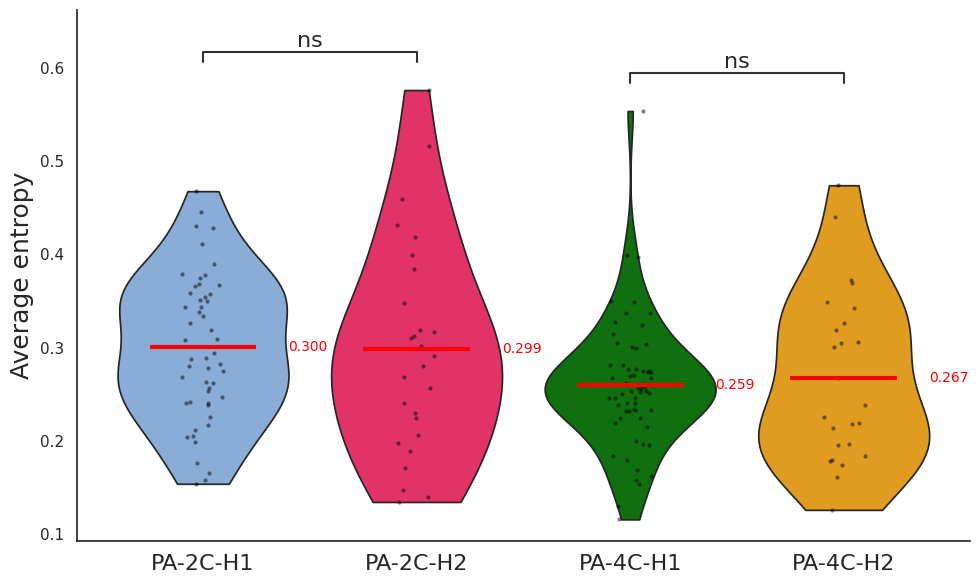

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# =========================
# data
# =========================
data = pd.read_csv('532_500k_w10_OneDnSE_CytoTRACE_TAD.txt', sep='\t')

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")

# =========================
# color mapping
# =========================
color_mapping = {
    "PA-2C-A1": "#7dace4",
    "PA-2C-A2": "#ff165d",
    "PA-4C-B1": "green",
    "PA-4C-B2": "orange",
}

x_label_mapping = {
    "PA-2C-A1": "PA-2C-H1",
    "PA-2C-A2": "PA-2C-H2",
    "PA-4C-B1": "PA-4C-H1",
    "PA-4C-B2": "PA-4C-H2",
}

trajectory_1 = ["PA-2C-A1", "PA-2C-A2", "PA-4C-B1", "PA-4C-B2"]
ordered_phenotypes = trajectory_1

# =========================
# mean values
# =========================
means = data.groupby("Phenotype2")["target_aver_OneDnSE"].mean().reindex(ordered_phenotypes)

# =========================
# figure
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

# =========================
# violin (clean)
# =========================
sns.violinplot(
    x="Phenotype2",
    y="target_aver_OneDnSE",
    data=data,
    order=ordered_phenotypes,
    palette=color_mapping,
    inner=None,
    cut=0,
    scale="width",
    ax=ax
)

# =========================
# strip (black)
# =========================
sns.stripplot(
    x="Phenotype2",
    y="target_aver_OneDnSE",
    data=data,
    order=ordered_phenotypes,
    color="black",
    size=3,
    alpha=0.5,
    jitter=True,
    ax=ax
)

# =========================
# mean line + value
# =========================
for i, g in enumerate(ordered_phenotypes):
    m = means[g]

    ax.hlines(
        y=m,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color="red",
        linewidth=3,
        zorder=5
    )

    ax.text(
        i + 0.4,
        m,
        f"{m:.3f}",
        color="red",
        fontsize=10,
        va="center"
    )

# =========================
# statistics
# =========================
pairs = [
    ("PA-2C-A1", "PA-2C-A2"),
    ("PA-4C-B1", "PA-4C-B2")
]

annotator = Annotator(
    ax,
    pairs,
    data=data,
    x="Phenotype2",
    y="target_aver_OneDnSE",
    order=ordered_phenotypes
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    fontsize=16
)

annotator.apply_and_annotate()

# =========================
# x labels
# =========================
ax.set_xticklabels(
    [x_label_mapping[x] for x in ordered_phenotypes],
    fontsize=16
)

# =========================
# labels
# =========================
ax.set_ylabel("Average entropy", fontsize=18)
ax.set_xlabel("")
#ax.set_title("PA TAD cluster entropy", fontsize=20)

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("PA_TAD_clusters_styled.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()